In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
customers = pd.read_csv("../data/raw/customers.csv")
restaurants = pd.read_csv("../data/raw/restaurants.csv")
orders = pd.read_csv("../data/raw/orders.csv")
deliveries = pd.read_csv("../data/raw/deliveries.csv")
reviews = pd.read_csv("../data/raw/reviews.csv")
payments = pd.read_csv("../data/raw/payments.csv")
drivers = pd.read_csv("../data/raw/drivers.csv")

# Display dataset sizes
print("Customers:", customers.shape)
print("Restaurants:", restaurants.shape)
print("Orders:", orders.shape)
print("Deliveries:", deliveries.shape)
print("Reviews:", reviews.shape)
print("Payments:", payments.shape)
print("Drivers:", drivers.shape)

Customers: (500, 4)
Restaurants: (50, 5)
Orders: (3000, 6)
Deliveries: (3000, 7)
Reviews: (3000, 6)
Payments: (3000, 5)
Drivers: (100, 3)


In [82]:
# Display column names for each dataset

datasets = {
    "Customers": customers,
    "Restaurants": restaurants,
    "Orders": orders,
    "Deliveries": deliveries,
    "Reviews": reviews,
    "Payments": payments,
    "Drivers": drivers
}

for name, df in datasets.items():
    print(f"\n{name} Columns:")
    print(df.columns.tolist())


Customers Columns:
['customer_id', 'age', 'city', 'signup_date']

Restaurants Columns:
['restaurant_id', 'restaurant_name', 'cuisine', 'rating', 'avg_prep_time_minutes']

Orders Columns:
['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'order_status']

Deliveries Columns:
['delivery_id', 'order_id', 'driver_id', 'distance_km', 'delivery_time_minutes', 'weather', 'traffic']

Reviews Columns:
['review_id', 'order_id', 'customer_id', 'review_text', 'sentiment', 'review_date']

Payments Columns:
['payment_id', 'order_id', 'payment_method', 'tip_amount', 'payment_status']

Drivers Columns:
['driver_id', 'experience_years', 'driver_rating']


In [83]:
# Check missing values and duplicate rows in each dataset

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    
    print("Missing values:")
    print(df.isnull().sum())
    
    print("Duplicate rows:", df.duplicated().sum())


--- Customers ---
Missing values:
customer_id    0
age            0
city           0
signup_date    0
dtype: int64
Duplicate rows: 0

--- Restaurants ---
Missing values:
restaurant_id            0
restaurant_name          0
cuisine                  0
rating                   0
avg_prep_time_minutes    0
dtype: int64
Duplicate rows: 0

--- Orders ---
Missing values:
order_id           0
customer_id        0
restaurant_id      0
order_timestamp    0
order_amount       0
order_status       0
dtype: int64
Duplicate rows: 0

--- Deliveries ---
Missing values:
delivery_id              0
order_id                 0
driver_id                0
distance_km              0
delivery_time_minutes    0
weather                  0
traffic                  0
dtype: int64
Duplicate rows: 0

--- Reviews ---
Missing values:
review_id      0
order_id       0
customer_id    0
review_text    0
sentiment      0
review_date    0
dtype: int64
Duplicate rows: 0

--- Payments ---
Missing values:
payment_id        

In [84]:
# Summarize data quality across all datasets

quality_summary = []

for name, df in datasets.items():
    quality_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

quality_df = pd.DataFrame(quality_summary)
display(quality_df)

,Dataset,Rows,Missing Values,Duplicate Rows
0,Customers,500,0,0
1,Restaurants,50,0,0
2,Orders,3000,0,0
3,Deliveries,3000,0,0
4,Reviews,3000,0,0
5,Payments,3000,0,0
6,Drivers,100,0,0


In [85]:
# Inspect order statuses
print("Order Status Values:")
print(orders["order_status"].value_counts())

# Check order amount and timestamp
print("\nOrder Amount Summary:")
print(orders["order_amount"].describe())

print("\nOrder Timestamp Sample:")
print(orders["order_timestamp"].head())

# Check review columns and sample values
print("\nReview Sample:")
display(reviews.head())

# Check delivery columns and sample values
print("\nDelivery Sample:")
display(deliveries.head())

Order Status Values:
order_status
Delivered    2635
Cancelled     217
Preparing     148
Name: count, dtype: int64

Order Amount Summary:
count    3000.00000
mean      800.43155
std       402.59267
min       100.26000
25%       464.69000
50%       798.32000
75%      1145.86750
max      1499.64000
Name: order_amount, dtype: float64

Order Timestamp Sample:
0    2025-09-17 12:00:00
1    2025-09-27 15:00:00
2    2025-04-30 07:00:00
3    2025-02-19 01:00:00
4    2025-07-18 08:00:00
Name: order_timestamp, dtype: object

Review Sample:


,review_id,order_id,customer_id,review_text,sentiment,review_date
0,1,1,258,Amazing experience,Positive,2025-09-17 12:00:00
1,2,2,180,Fresh food delivered on time,Positive,2025-09-27 15:00:00
2,3,3,487,Loved the food and service,Positive,2025-04-30 07:00:00
3,4,4,373,Order was incorrect,Negative,2025-02-19 01:00:00
4,5,5,172,Poor packaging and bad service,Negative,2025-07-18 08:00:00



Delivery Sample:


,delivery_id,order_id,driver_id,distance_km,delivery_time_minutes,weather,traffic
0,1,1,42,10.82,57,Rainy,Low
1,2,2,95,3.74,19,Cloudy,Low
2,3,3,50,12.82,90,Clear,High
3,4,4,60,9.78,39,Cloudy,High
4,5,5,1,18.78,44,Rainy,Medium


In [86]:
# Convert order timestamps to datetime
orders["order_timestamp"] = pd.to_datetime(orders["order_timestamp"])

# Separate delivered orders
delivered_orders = orders[orders["order_status"] == "Delivered"].copy()

# Extract date and hour information
orders["order_date"] = orders["order_timestamp"].dt.date
orders["order_hour"] = orders["order_timestamp"].dt.hour
orders["is_weekend"] = orders["order_timestamp"].dt.dayofweek >= 5
orders["is_late_night"] = (
    (orders["order_hour"] >= 22) | (orders["order_hour"] < 5)
)

# Calculate customer order metrics using all orders
customer_features = orders.groupby("customer_id").agg(
    total_orders=("order_id", "count"),
    weekend_orders=("is_weekend", "sum"),
    late_night_orders=("is_late_night", "sum")
).reset_index()

# Calculate spending metrics using delivered orders only
customer_spending = delivered_orders.groupby("customer_id").agg(
    total_spending=("order_amount", "sum"),
    avg_order_value=("order_amount", "mean")
).reset_index()

# Merge spending metrics into customer features
customer_features = customer_features.merge(
    customer_spending, on="customer_id", how="left"
)

# Calculate average rating given by each customer
customer_reviews = reviews.merge(
    orders[["order_id", "customer_id"]],
    on="order_id",
    how="left",
    suffixes=("_review", "_order")
)

# Use the customer ID recorded in the review
customer_reviews["customer_id"] = customer_reviews["customer_id_review"]

customer_ratings = customer_reviews.groupby("customer_id").agg(
    avg_rating_given=("sentiment", lambda x: (x == "Positive").mean())
).reset_index()

customer_features = customer_features.merge(
    customer_ratings, on="customer_id", how="left"
)

# Include customers with no orders
customer_features = customers[["customer_id"]].merge(
    customer_features, on="customer_id", how="left"
)

# Fill missing metric values with zero
metric_columns = [
    "total_orders", "weekend_orders", "late_night_orders",
    "total_spending", "avg_order_value", "avg_rating_given"
]
customer_features[metric_columns] = customer_features[metric_columns].fillna(0)

# Display the result
print("Customer feature table shape:", customer_features.shape)
display(customer_features.head())

Customer feature table shape: (500, 7)


,customer_id,total_orders,weekend_orders,late_night_orders,total_spending,avg_order_value,avg_rating_given
0,1,9.0,4.0,0.0,4408.20,551.0250,0.444444
1,2,8.0,3.0,2.0,6217.58,777.1975,0.625000
2,3,6.0,0.0,0.0,3855.51,771.1020,0.333333
3,4,6.0,2.0,3.0,4536.84,756.1400,0.666667
4,5,4.0,3.0,1.0,2892.96,964.3200,0.500000


In [87]:
# Calculate total orders and cancellations for each restaurant
restaurant_order_metrics = orders.groupby("restaurant_id").agg(
    total_orders=("order_id", "count"),
    cancelled_orders=("order_status", lambda x: (x == "Cancelled").sum())
).reset_index()

# Calculate revenue from delivered orders only
restaurant_revenue = delivered_orders.groupby("restaurant_id").agg(
    total_revenue=("order_amount", "sum")
).reset_index()

# Calculate cancellation rate as a percentage
restaurant_order_metrics["cancellation_rate"] = (
    restaurant_order_metrics["cancelled_orders"]
    / restaurant_order_metrics["total_orders"] * 100
)

# Calculate average delivery time for each restaurant
restaurant_delivery = delivered_orders[["order_id", "restaurant_id"]].merge(
    deliveries[["order_id", "delivery_time_minutes"]],
    on="order_id",
    how="left"
)

restaurant_delivery_metrics = restaurant_delivery.groupby("restaurant_id").agg(
    avg_delivery_time=("delivery_time_minutes", "mean")
).reset_index()

# Combine restaurant details and calculated metrics
restaurant_features = restaurants.merge(
    restaurant_order_metrics, on="restaurant_id", how="left"
)

restaurant_features = restaurant_features.merge(
    restaurant_revenue, on="restaurant_id", how="left"
)

restaurant_features = restaurant_features.merge(
    restaurant_delivery_metrics, on="restaurant_id", how="left"
)

# Fill missing metric values
metric_columns = [
    "total_orders", "cancelled_orders", "cancellation_rate",
    "total_revenue", "avg_delivery_time"
]
restaurant_features[metric_columns] = (
    restaurant_features[metric_columns].fillna(0)
)

# Display selected restaurant features
print("Restaurant feature table shape:", restaurant_features.shape)

display(
    restaurant_features[
        [
            "restaurant_id", "restaurant_name", "cuisine",
            "rating", "avg_prep_time_minutes", "total_orders",
            "total_revenue", "cancellation_rate", "avg_delivery_time"
        ]
    ].head()
)

Restaurant feature table shape: (50, 10)


,restaurant_id,restaurant_name,cuisine,rating,avg_prep_time_minutes,total_orders,total_revenue,cancellation_rate,avg_delivery_time
0,1,Restaurant_1,Indian,3.0,36,62,43693.05,6.451613,53.339286
1,2,Restaurant_2,Fast Food,3.7,15,61,41782.38,11.475410,44.820000
2,3,Restaurant_3,Fast Food,2.5,18,61,46240.91,6.557377,53.178571
3,4,Restaurant_4,Italian,4.0,15,53,37476.63,9.433962,44.583333
4,5,Restaurant_5,Mexican,4.0,18,53,34857.55,3.773585,47.979167


In [88]:
# Calculate the number of days each customer placed orders
customer_order_frequency = orders.groupby("customer_id").agg(
    active_order_days=("order_date", "nunique")
).reset_index()

# Calculate the total orders for each customer
customer_order_frequency["total_orders"] = (
    orders.groupby("customer_id")["order_id"].count().values
)

# Calculate ordering frequency
customer_order_frequency["ordering_frequency"] = (
    customer_order_frequency["total_orders"] /
    customer_order_frequency["active_order_days"]
)

# Keep only the customer ID and ordering frequency
customer_order_frequency = customer_order_frequency[
    ["customer_id", "ordering_frequency"]
]

# Add ordering frequency to the existing customer features
customer_features = customer_features.merge(
    customer_order_frequency,
    on="customer_id",
    how="left"
)

# Display the updated customer features
customer_features.head()

,customer_id,total_orders,weekend_orders,late_night_orders,total_spending,avg_order_value,avg_rating_given,ordering_frequency
0,1,9.0,4.0,0.0,4408.20,551.0250,0.444444,1.0
1,2,8.0,3.0,2.0,6217.58,777.1975,0.625000,1.0
2,3,6.0,0.0,0.0,3855.51,771.1020,0.333333,1.0
3,4,6.0,2.0,3.0,4536.84,756.1400,0.666667,1.0
4,5,4.0,3.0,1.0,2892.96,964.3200,0.500000,1.0


In [89]:
print(customer_features.columns.tolist())

['customer_id', 'total_orders', 'weekend_orders', 'late_night_orders', 'total_spending', 'avg_order_value', 'avg_rating_given', 'ordering_frequency']


In [90]:
customer_feature_columns = [
    "total_orders",
    "ordering_frequency",
    "weekend_orders",
    "late_night_orders",
    "total_spending",
    "avg_order_value",
    "avg_rating_given"
]

In [91]:
X_customers = customer_features[customer_feature_columns].copy()

customer_scaler = StandardScaler()
X_customers_scaled = customer_scaler.fit_transform(X_customers)

print("Customer features shape:", X_customers_scaled.shape)

Customer features shape: (500, 7)


In [92]:
from sklearn.preprocessing import StandardScaler

# Select numerical features for customer clustering
customer_feature_columns = [
    "total_orders",
    "ordering_frequency",
    "weekend_orders",
    "late_night_orders",
    "total_spending",
    "avg_order_value",
    "avg_rating_given"
]

X_customers = customer_features[customer_feature_columns].copy()

# Standardize the features
customer_scaler = StandardScaler()
X_customers_scaled = customer_scaler.fit_transform(X_customers)

print("Customer features before scaling:", X_customers.shape)
print("Customer features after scaling:", X_customers_scaled.shape)
print("\nFirst 5 scaled customer records:")
display(pd.DataFrame(
    X_customers_scaled,
    columns=customer_feature_columns
).head())

Customer features before scaling: (500, 7)
Customer features after scaling: (500, 7)

First 5 scaled customer records:


,total_orders,ordering_frequency,weekend_orders,late_night_orders,total_spending,avg_order_value,avg_rating_given
0,1.226791,-0.184089,1.756111,-1.421967,0.112871,-1.214586,-0.597863
1,0.817861,-0.184089,0.976310,0.145803,1.015130,-0.064350,0.186205
2,0.000000,-0.184089,-1.363092,-1.421967,-0.162731,-0.095349,-1.080366
3,0.000000,-0.184089,0.196510,0.929688,0.177018,-0.171441,0.367144
4,-0.817861,-0.184089,0.976310,-0.638082,-0.642713,0.887292,-0.356611


In [94]:
print(restaurant_features.columns.tolist())

['restaurant_id', 'restaurant_name', 'cuisine', 'rating', 'avg_prep_time_minutes', 'total_orders', 'cancelled_orders', 'cancellation_rate', 'total_revenue', 'avg_delivery_time']


In [100]:
from sklearn.preprocessing import StandardScaler

# Select numerical features for restaurant clustering
restaurant_feature_columns = [
    "rating",
    "avg_prep_time_minutes",
    "total_orders",
    "total_revenue",
    "cancellation_rate",
    "avg_delivery_time"
]

X_restaurants = restaurant_features[restaurant_feature_columns].copy()

# Standardize the features
restaurant_scaler = StandardScaler()
X_restaurants_scaled = restaurant_scaler.fit_transform(X_restaurants)

print("Restaurant features before scaling:", X_restaurants.shape)
print("Restaurant features after scaling:", X_restaurants_scaled.shape)

display(pd.DataFrame(
    X_restaurants_scaled,
    columns=restaurant_feature_columns
).head())

Restaurant features before scaling: (50, 6)
Restaurant features after scaling: (50, 6)


,rating,avg_prep_time_minutes,total_orders,total_revenue,cancellation_rate,avg_delivery_time
0,-1.020517,1.145388,0.281942,0.306359,-0.228649,1.458904
1,-0.092774,-1.324134,0.140971,-0.005902,1.270828,-1.656634
2,-1.683190,-0.971345,0.140971,0.722756,-0.197081,1.400130
3,0.304830,-1.324134,-0.986797,-0.709591,0.661507,-1.743184
4,0.304830,-0.971345,-0.986797,-1.137628,-1.027974,-0.501314


In [103]:
# Check missing values in customer clustering features
print("Missing values before fixing:")
print(X_customers.isnull().sum())

print("\nTotal missing values:", X_customers.isnull().sum().sum())

Missing values before fixing:
total_orders          0
ordering_frequency    2
weekend_orders        0
late_night_orders     0
total_spending        0
avg_order_value       0
avg_rating_given      0
dtype: int64

Total missing values: 2


In [104]:
import numpy as np

print("Infinite values in each feature:")
print(np.isinf(X_customers).sum())

Infinite values in each feature:
total_orders          0
ordering_frequency    0
weekend_orders        0
late_night_orders     0
total_spending        0
avg_order_value       0
avg_rating_given      0
dtype: int64


In [105]:
# Fill missing ordering_frequency values with the median
customer_features["ordering_frequency"] = customer_features["ordering_frequency"].fillna(
    customer_features["ordering_frequency"].median()
)

# Verify that missing values are handled
print("Missing values after fixing:")
print(customer_features[customer_feature_columns].isnull().sum())

Missing values after fixing:
total_orders          0
ordering_frequency    0
weekend_orders        0
late_night_orders     0
total_spending        0
avg_order_value       0
avg_rating_given      0
dtype: int64


In [106]:
from sklearn.preprocessing import StandardScaler

# Select customer clustering features again
X_customers = customer_features[customer_feature_columns].copy()

# Scale the features
customer_scaler = StandardScaler()
X_customers_scaled = customer_scaler.fit_transform(X_customers)

print("Customer data shape:", X_customers_scaled.shape)
print("Missing values in scaled data:", X_customers.isnull().sum().sum())

Customer data shape: (500, 7)
Missing values in scaled data: 0


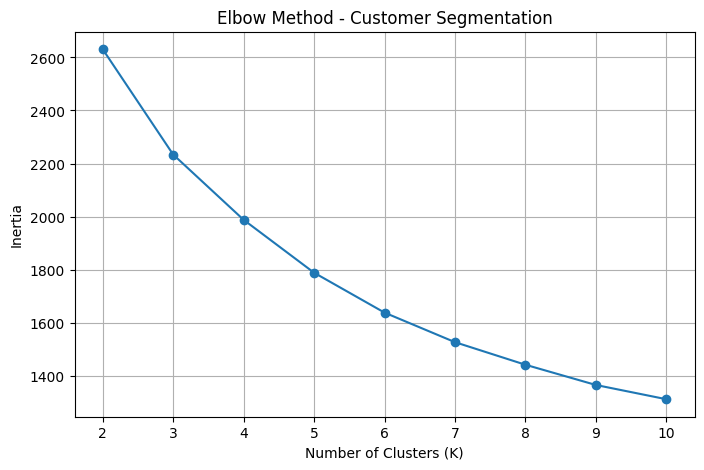

In [129]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Test different numbers of clusters
inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_customers_scaled)
    inertias.append(model.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method - Customer Segmentation")
plt.xticks(list(k_values))
plt.grid(True)

plt.savefig(
    "../outputs/visualizations/customer_elbow.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

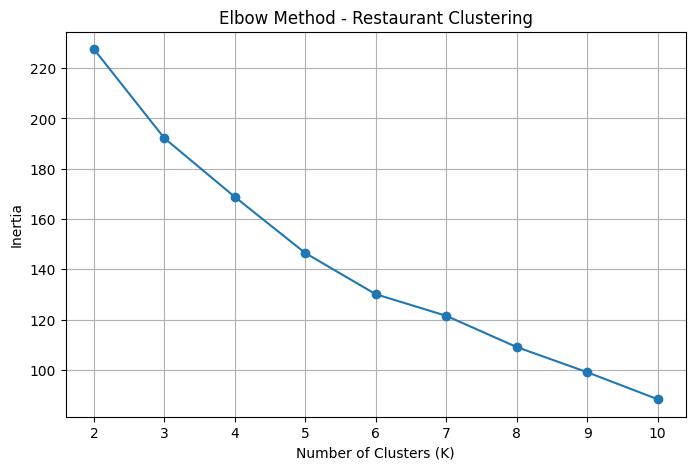

In [139]:
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker="o")
plt.title("Elbow Method - Restaurant Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(True)

plt.savefig("../outputs/visualizations/restaurant_elbow.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [108]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

# Evaluate customer clustering
customer_silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_customers_scaled)
    score = silhouette_score(X_customers_scaled, labels)

    customer_silhouette_scores.append({
        "K": k,
        "Silhouette Score": round(score, 4)
    })

customer_silhouette_results = pd.DataFrame(
    customer_silhouette_scores
)

print("Customer Clustering Evaluation")
display(customer_silhouette_results)


# Evaluate restaurant clustering
restaurant_silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_restaurants_scaled)
    score = silhouette_score(X_restaurants_scaled, labels)

    restaurant_silhouette_scores.append({
        "K": k,
        "Silhouette Score": round(score, 4)
    })

restaurant_silhouette_results = pd.DataFrame(
    restaurant_silhouette_scores
)

print("Restaurant Clustering Evaluation")
display(restaurant_silhouette_results)

Customer Clustering Evaluation


,K,Silhouette Score
0,2,0.2303
1,3,0.2476
2,4,0.1959
3,5,0.1700
4,6,0.1652
5,7,0.1685
6,8,0.1604
7,9,0.1634
8,10,0.1602


Restaurant Clustering Evaluation


,K,Silhouette Score
0,2,0.2060
1,3,0.1997
2,4,0.1872
3,5,0.1979
4,6,0.2122
5,7,0.2000
6,8,0.2000
7,9,0.2184
8,10,0.2247


In [109]:
from sklearn.cluster import KMeans

# Selected K values - update after reviewing the results
customer_best_k = 3
restaurant_best_k = 3

# Final customer clustering model
customer_kmeans = KMeans(
    n_clusters=customer_best_k,
    random_state=42,
    n_init=10
)

customer_features["customer_cluster"] = (
    customer_kmeans.fit_predict(X_customers_scaled)
)

# Final restaurant clustering model
restaurant_kmeans = KMeans(
    n_clusters=restaurant_best_k,
    random_state=42,
    n_init=10
)

restaurant_features["restaurant_cluster"] = (
    restaurant_kmeans.fit_predict(X_restaurants_scaled)
)

print("Customer clustering completed.")
print("Restaurant clustering completed.")

print("\nCustomer cluster counts:")
print(customer_features["customer_cluster"].value_counts().sort_index())

print("\nRestaurant cluster counts:")
print(restaurant_features["restaurant_cluster"].value_counts().sort_index())

Customer clustering completed.
Restaurant clustering completed.

Customer cluster counts:
customer_cluster
0    220
1    264
2     16
Name: count, dtype: int64

Restaurant cluster counts:
restaurant_cluster
0    22
1    13
2    15
Name: count, dtype: int64


In [110]:
customer_cluster_summary = customer_features.groupby(
    "customer_cluster"
).agg(
    customer_count=("customer_cluster", "size"),
    avg_total_orders=("total_orders", "mean"),
    avg_ordering_frequency=("ordering_frequency", "mean"),
    avg_weekend_orders=("weekend_orders", "mean"),
    avg_late_night_orders=("late_night_orders", "mean"),
    avg_total_spending=("total_spending", "mean"),
    avg_order_value=("avg_order_value", "mean"),
    avg_rating_given=("avg_rating_given", "mean")
).round(2)

print("Customer Cluster Profiles")
display(customer_cluster_summary)

Customer Cluster Profiles


,customer_count,avg_total_orders,avg_ordering_frequency,avg_weekend_orders,avg_late_night_orders,avg_total_spending,avg_order_value,avg_rating_given
customer_cluster,,,,,,,,
0,220,7.99,1.00,2.59,2.60,5774.83,820.66,0.59
1,264,4.32,1.00,1.05,1.14,2871.58,766.99,0.57
2,16,6.38,1.21,1.69,2.19,3897.67,743.46,0.63


In [111]:
restaurant_cluster_summary = restaurant_features.groupby(
    "restaurant_cluster"
).agg(
    restaurant_count=("restaurant_cluster", "size"),
    avg_rating=("rating", "mean"),
    avg_prep_time=("avg_prep_time_minutes", "mean"),
    avg_total_orders=("total_orders", "mean"),
    avg_total_revenue=("total_revenue", "mean"),
    avg_cancellation_rate=("cancellation_rate", "mean"),
    avg_delivery_time=("avg_delivery_time", "mean")
).round(2)

print("Restaurant Cluster Profiles")
display(restaurant_cluster_summary)

Restaurant Cluster Profiles


,restaurant_count,avg_rating,avg_prep_time,avg_total_orders,avg_total_revenue,avg_cancellation_rate,avg_delivery_time
restaurant_cluster,,,,,,,
0,22,3.80,23.86,66.00,47336.05,6.17,49.59
1,13,3.88,19.31,55.31,37594.85,9.25,47.38
2,15,3.62,35.80,55.27,37386.56,6.99,50.70


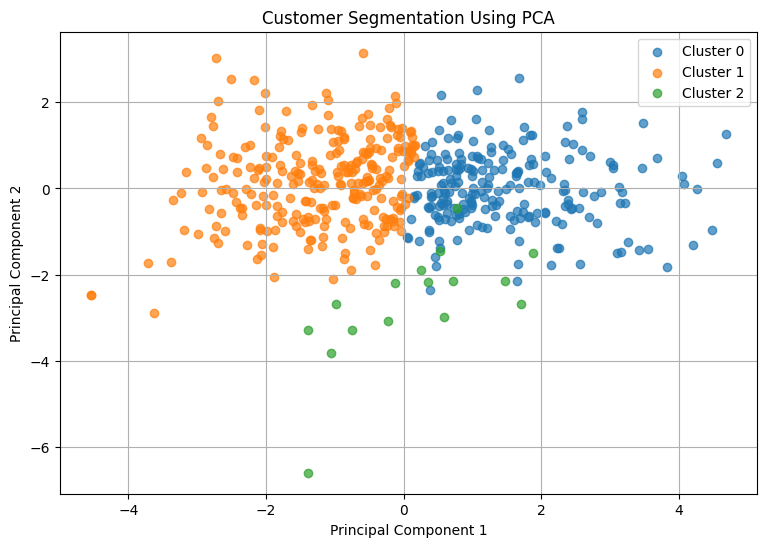

Variance explained by two PCA components: 54.69 %


In [130]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce customer features to two dimensions
customer_pca = PCA(n_components=2)
customer_pca_results = customer_pca.fit_transform(X_customers_scaled)

# Create a DataFrame for visualization
customer_pca_df = pd.DataFrame(
    customer_pca_results,
    columns=["PCA1", "PCA2"]
)

customer_pca_df["Cluster"] = customer_features["customer_cluster"].values

# Plot the clusters
plt.figure(figsize=(9, 6))

for cluster in sorted(customer_pca_df["Cluster"].unique()):
    cluster_data = customer_pca_df[
        customer_pca_df["Cluster"] == cluster
    ]

    plt.scatter(
        cluster_data["PCA1"],
        cluster_data["PCA2"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation Using PCA")
plt.legend()
plt.grid(True)

plt.savefig(
    "../outputs/visualizations/customer_kmeans_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display the variance retained by the two components
print(
    "Variance explained by two PCA components:",
    round(customer_pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [113]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Compare different numbers of restaurant clusters
for k in [2, 3, 4, 5]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_restaurants_scaled)
    score = silhouette_score(X_restaurants_scaled, labels)

    print(f"K = {k} | Silhouette Score = {score:.4f}")

K = 2 | Silhouette Score = 0.2060
K = 3 | Silhouette Score = 0.1997
K = 4 | Silhouette Score = 0.1872
K = 5 | Silhouette Score = 0.1979


In [114]:
# Train the final K-Means model with 2 clusters
restaurant_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

restaurant_features["restaurant_cluster"] = restaurant_kmeans.fit_predict(
    X_restaurants_scaled
)

# Count restaurants in each cluster
print("Restaurants in each cluster:")
print(
    restaurant_features["restaurant_cluster"]
    .value_counts()
    .sort_index()
)

# Summarize restaurant performance by cluster
restaurant_cluster_profile = restaurant_features.groupby(
    "restaurant_cluster"
)[restaurant_feature_columns].mean().round(2)

print("\nRestaurant Cluster Profiles:")
display(restaurant_cluster_profile)

Restaurants in each cluster:
restaurant_cluster
0    28
1    22
Name: count, dtype: int64

Restaurant Cluster Profiles:


,rating,avg_prep_time_minutes,total_orders,total_revenue,cancellation_rate,avg_delivery_time
restaurant_cluster,,,,,,
0,3.82,23.46,65.04,46179.99,7.28,49.67
1,3.70,29.82,53.59,36267.50,7.14,48.95


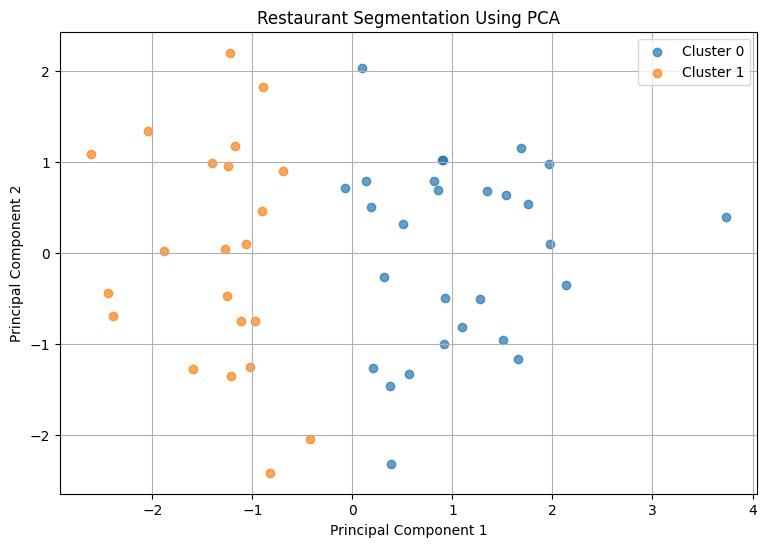

Variance explained by two PCA components: 52.47 %


In [131]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Reduce restaurant features to two dimensions
restaurant_pca = PCA(n_components=2)

restaurant_pca_results = restaurant_pca.fit_transform(
    X_restaurants_scaled
)

# Create a DataFrame for visualization
restaurant_pca_df = pd.DataFrame(
    restaurant_pca_results,
    columns=["PCA1", "PCA2"]
)

restaurant_pca_df["Cluster"] = (
    restaurant_features["restaurant_cluster"].values
)

# Plot the restaurant clusters
plt.figure(figsize=(9, 6))

for cluster in sorted(restaurant_pca_df["Cluster"].unique()):
    cluster_data = restaurant_pca_df[
        restaurant_pca_df["Cluster"] == cluster
    ]

    plt.scatter(
        cluster_data["PCA1"],
        cluster_data["PCA2"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Restaurant Segmentation Using PCA")
plt.legend()
plt.grid(True)

plt.savefig(
    "../outputs/visualizations/restaurant_kmeans_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display the variance explained
print(
    "Variance explained by two PCA components:",
    round(
        restaurant_pca.explained_variance_ratio_.sum() * 100, 2
    ),
    "%"
)

In [116]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np

# Train DBSCAN on scaled customer features
customer_dbscan = DBSCAN(eps=1.5, min_samples=10)

customer_dbscan_labels = customer_dbscan.fit_predict(
    X_customers_scaled
)

# Save DBSCAN labels
customer_features["customer_dbscan_cluster"] = customer_dbscan_labels

# Count clusters and noise points
unique_labels, counts = np.unique(
    customer_dbscan_labels,
    return_counts=True
)

print("Customer DBSCAN Results:")
for label, count in zip(unique_labels, counts):
    if label == -1:
        print(f"Noise points: {count}")
    else:
        print(f"Cluster {label}: {count} customers")

print("\nNumber of clusters excluding noise:", len(set(customer_dbscan_labels)) - (1 if -1 in customer_dbscan_labels else 0))

Customer DBSCAN Results:
Noise points: 56
Cluster 0: 444 customers

Number of clusters excluding noise: 1


In [118]:
from sklearn.cluster import DBSCAN
import numpy as np

# Test different DBSCAN parameter combinations
for eps in [0.8, 1.0, 1.2, 1.5]:
    for min_samples in [5, 10]:
        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_customers_scaled)

        # Count clusters, excluding noise label -1
        n_clusters = len(set(labels) - {-1})
        n_noise = int(np.sum(labels == -1))

        print(
            f"eps={eps}, min_samples={min_samples} | "
            f"Clusters={n_clusters}, Noise points={n_noise}"
        )

eps=0.8, min_samples=5 | Clusters=7, Noise points=416
eps=0.8, min_samples=10 | Clusters=0, Noise points=500
eps=1.0, min_samples=5 | Clusters=4, Noise points=201
eps=1.0, min_samples=10 | Clusters=1, Noise points=355
eps=1.2, min_samples=5 | Clusters=1, Noise points=103
eps=1.2, min_samples=10 | Clusters=2, Noise points=155
eps=1.5, min_samples=5 | Clusters=1, Noise points=41
eps=1.5, min_samples=10 | Clusters=1, Noise points=56


In [134]:
# Train DBSCAN using the selected parameters
customer_dbscan = DBSCAN(
    eps=1.0,
    min_samples=5
)

customer_features["customer_dbscan_cluster"] = (
    customer_dbscan.fit_predict(X_customers_scaled)
)

# Count customers in each cluster, including noise
print("Final Customer DBSCAN Results:")
print(
    customer_features["customer_dbscan_cluster"]
    .value_counts()
    .sort_index()
)

# Calculate Silhouette Score if at least 2 clusters exist
labels = customer_features["customer_dbscan_cluster"]
non_noise_mask = labels != -1
non_noise_labels = labels[non_noise_mask]

if len(set(non_noise_labels)) >= 2:
    score = silhouette_score(
        X_customers_scaled[non_noise_mask],
        non_noise_labels
    )
    print(f"\nSilhouette Score (excluding noise): {score:.4f}")
else:
    print("\nSilhouette Score cannot be calculated for fewer than 2 non-noise clusters.")

Final Customer DBSCAN Results:
customer_dbscan_cluster
-1    201
 0    278
 1     14
 2      5
 3      2
Name: count, dtype: int64

Silhouette Score (excluding noise): -0.0057


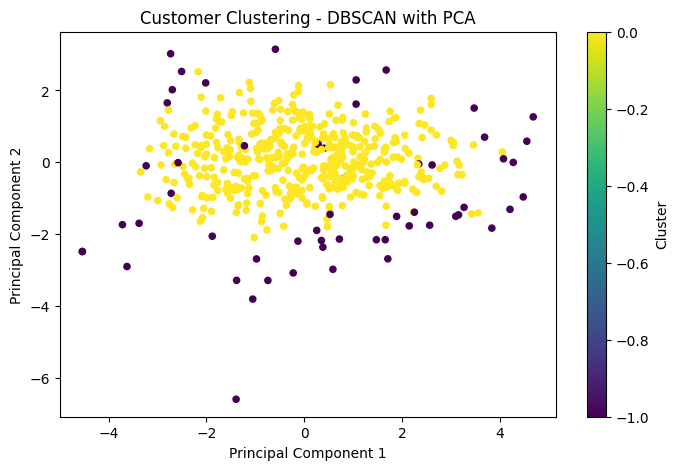

In [136]:
customer_pca = PCA(n_components=2)
customer_pca_result = customer_pca.fit_transform(X_customers_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    customer_pca_result[:, 0],
    customer_pca_result[:, 1],
    c=customer_dbscan_labels,
    cmap="viridis",
    s=20
)

plt.title("Customer Clustering - DBSCAN with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.savefig("../outputs/visualizations/customer_dbscan_pca.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [125]:
from sklearn.cluster import DBSCAN
import numpy as np

# Compare DBSCAN parameter combinations for restaurants
for eps in [0.8, 1.0, 1.2, 1.5, 2.0]:
    for min_samples in [3, 5]:
        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_restaurants_scaled)

        # Count clusters and noise points
        n_clusters = len(set(labels) - {-1})
        n_noise = int(np.sum(labels == -1))

        print(
            f"eps={eps}, min_samples={min_samples} | "
            f"Clusters={n_clusters}, Noise points={n_noise}"
        )

eps=0.8, min_samples=3 | Clusters=0, Noise points=50
eps=0.8, min_samples=5 | Clusters=0, Noise points=50
eps=1.0, min_samples=3 | Clusters=0, Noise points=50
eps=1.0, min_samples=5 | Clusters=0, Noise points=50
eps=1.2, min_samples=3 | Clusters=0, Noise points=50
eps=1.2, min_samples=5 | Clusters=0, Noise points=50
eps=1.5, min_samples=3 | Clusters=4, Noise points=31
eps=1.5, min_samples=5 | Clusters=0, Noise points=50
eps=2.0, min_samples=3 | Clusters=3, Noise points=5
eps=2.0, min_samples=5 | Clusters=2, Noise points=14


In [120]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Apply DBSCAN to scaled restaurant features
restaurant_dbscan = DBSCAN(
    eps=1.5,
    min_samples=3
)

restaurant_features["restaurant_dbscan_cluster"] = (
    restaurant_dbscan.fit_predict(X_restaurants_scaled)
)

# Display the number of restaurants in each cluster
print("Restaurant DBSCAN Results:")
print(
    restaurant_features["restaurant_dbscan_cluster"]
    .value_counts()
    .sort_index()
)

# Evaluate clusters, excluding noise points
labels = restaurant_features["restaurant_dbscan_cluster"]
non_noise_mask = labels != -1
non_noise_labels = labels[non_noise_mask]

if len(set(non_noise_labels)) >= 2:
    score = silhouette_score(
        X_restaurants_scaled[non_noise_mask],
        non_noise_labels
    )
    print(f"\nSilhouette Score (excluding noise): {score:.4f}")
else:
    print("\nSilhouette Score unavailable: fewer than 2 non-noise clusters.")

Restaurant DBSCAN Results:
restaurant_dbscan_cluster
-1    31
 0     4
 1     3
 2     9
 3     3
Name: count, dtype: int64

Silhouette Score (excluding noise): 0.2741


In [126]:
# Customer DBSCAN cluster profiles
customer_dbscan_profile = customer_features.groupby(
    "customer_dbscan_cluster"
).agg(
    customer_count=("customer_dbscan_cluster", "size"),
    avg_total_orders=("total_orders", "mean"),
    avg_total_spending=("total_spending", "mean"),
    avg_order_value=("avg_order_value", "mean"),
    avg_weekend_orders=("weekend_orders", "mean"),
    avg_late_night_orders=("late_night_orders", "mean")
).round(2)

print("CUSTOMER DBSCAN CLUSTER PROFILES")
display(customer_dbscan_profile)


# Restaurant DBSCAN cluster profiles
restaurant_dbscan_profile = restaurant_features.groupby(
    "restaurant_dbscan_cluster"
).agg(
    restaurant_count=("restaurant_dbscan_cluster", "size"),
    avg_total_orders=("total_orders", "mean"),
    avg_total_revenue=("total_revenue", "mean"),
    avg_rating=("rating", "mean"),
    avg_prep_time=("avg_prep_time_minutes", "mean"),
    avg_cancellation_rate=("cancellation_rate", "mean"),
    avg_delivery_time=("avg_delivery_time", "mean")
).round(2)

print("RESTAURANT DBSCAN CLUSTER PROFILES")
display(restaurant_dbscan_profile)

CUSTOMER DBSCAN CLUSTER PROFILES


,customer_count,avg_total_orders,avg_total_spending,avg_order_value,avg_weekend_orders,avg_late_night_orders
customer_dbscan_cluster,,,,,,
-1,201,6.50,4426.60,793.22,1.82,2.11
0,278,5.78,4111.90,792.30,1.72,1.67
1,14,2.29,1367.50,693.16,0.71,0.36
2,5,6.80,5201.84,818.19,3.00,1.20
3,2,10.50,6457.60,717.51,3.00,3.00


RESTAURANT DBSCAN CLUSTER PROFILES


,restaurant_count,avg_total_orders,avg_total_revenue,avg_rating,avg_prep_time,avg_cancellation_rate,avg_delivery_time
restaurant_dbscan_cluster,,,,,,,
-1,31,62.42,43678.40,3.75,25.13,8.18,49.39
0,4,49.50,34353.06,4.42,20.00,4.05,47.30
1,3,51.00,34552.48,2.83,34.67,7.79,51.95
2,9,58.78,39927.59,3.77,33.44,4.45,49.50
3,3,61.67,45492.07,4.07,16.33,9.26,48.57


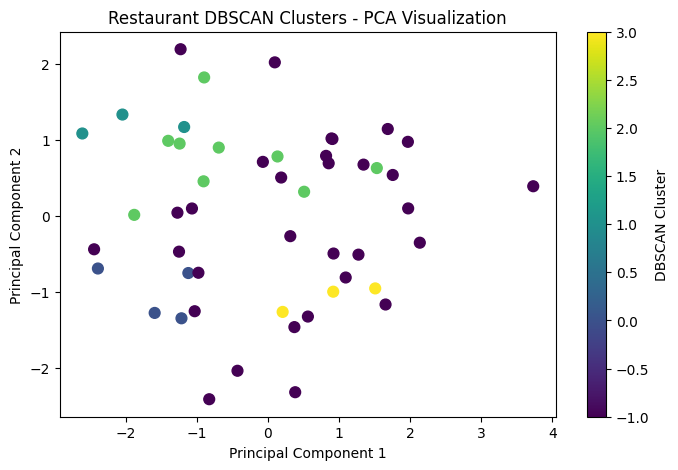

Variance explained by two components: 52.47%


In [132]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce restaurant features to 2 dimensions
restaurant_pca = PCA(n_components=2)
restaurant_pca_results = restaurant_pca.fit_transform(X_restaurants_scaled)

# Plot DBSCAN clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    restaurant_pca_results[:, 0],
    restaurant_pca_results[:, 1],
    c=restaurant_features["restaurant_dbscan_cluster"],
    cmap="viridis",
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Restaurant DBSCAN Clusters - PCA Visualization")
plt.colorbar(label="DBSCAN Cluster")

plt.savefig(
    "../outputs/visualizations/restaurant_dbscan_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display explained variance
explained_variance = restaurant_pca.explained_variance_ratio_.sum() * 100
print(f"Variance explained by two components: {explained_variance:.2f}%")

In [122]:
# Customer cluster profiles
customer_profile = customer_features.groupby("customer_cluster").agg({
    "total_orders": "mean",
    "total_spending": "mean",
    "avg_order_value": "mean",
    "weekend_orders": "mean",
    "late_night_orders": "mean"
}).round(2)

print("CUSTOMER CLUSTER PROFILES")
display(customer_profile)

# Restaurant cluster profiles
restaurant_profile = restaurant_features.groupby("restaurant_cluster").agg({
    "total_orders": "mean",
    "total_revenue": "mean",
    "rating": "mean",
    "avg_prep_time_minutes": "mean",
    "cancellation_rate": "mean",
    "avg_delivery_time": "mean"
}).round(2)

print("RESTAURANT CLUSTER PROFILES")
display(restaurant_profile)

CUSTOMER CLUSTER PROFILES


,total_orders,total_spending,avg_order_value,weekend_orders,late_night_orders
customer_cluster,,,,,
0,7.99,5774.83,820.66,2.59,2.60
1,4.32,2871.58,766.99,1.05,1.14
2,6.38,3897.67,743.46,1.69,2.19


RESTAURANT CLUSTER PROFILES


,total_orders,total_revenue,rating,avg_prep_time_minutes,cancellation_rate,avg_delivery_time
restaurant_cluster,,,,,,
0,65.04,46179.99,3.82,23.46,7.28,49.67
1,53.59,36267.50,3.70,29.82,7.14,48.95


In [123]:
import os

# Create the processed data folder if it doesn't exist
os.makedirs("../data/processed", exist_ok=True)

# Save customer features and cluster labels
customer_features.to_csv(
    "../data/processed/customer_segments.csv",
    index=False
)

# Save restaurant features and cluster labels
restaurant_features.to_csv(
    "../data/processed/restaurant_segments.csv",
    index=False
)

print("Customer and restaurant segmentation datasets saved successfully!")

Customer and restaurant segmentation datasets saved successfully!


In [124]:
print(customer_features.columns.tolist())

['customer_id', 'total_orders', 'weekend_orders', 'late_night_orders', 'total_spending', 'avg_order_value', 'avg_rating_given', 'ordering_frequency', 'customer_cluster', 'customer_dbscan_cluster']
